In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import gc
import kagglehub

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
dataset_path = kagglehub.dataset_download(
    "stefanoleone992/fifa-23-complete-player-dataset"
)

file_path = os.path.join(dataset_path, "male_players.csv")

print("Dataset path:", file_path)

Using Colab cache for faster access to the 'fifa-23-complete-player-dataset' dataset.
Dataset path: /kaggle/input/fifa-23-complete-player-dataset/male_players.csv


In [ ]:
selected_columns = [
    "sofifa_id",
    "short_name",
    "player_positions",
    "age",
    "overall",
    "potential",
    "value_eur",
    "wage_eur",
    "club_name",
    "league_name",
    "nationality_name",
    "pace",
    "shooting",
    "passing",
    "dribbling",
    "defending",
    "physic"
]

players = pd.read_csv(
    file_path,
    usecols=lambda col: col in selected_columns,
    low_memory=True
)

print("Dataset loaded successfully!")
print("Shape:", players.shape)

display(players.head())

Dataset loaded successfully!
Shape: (10003590, 16)


,short_name,player_positions,overall,potential,value_eur,wage_eur,age,league_name,club_name,nationality_name,pace,shooting,passing,dribbling,defending,physic
0,L. Messi,RW,91,91,54000000.0,195000.0,35,Ligue 1,Paris Saint Germain,Argentina,81.0,89.0,90.0,94.0,34.0,64.0
1,K. Benzema,"CF, ST",91,91,64000000.0,450000.0,34,La Liga,Real Madrid,France,80.0,88.0,83.0,87.0,39.0,78.0
2,R. Lewandowski,ST,91,91,84000000.0,420000.0,33,La Liga,FC Barcelona,Poland,75.0,91.0,79.0,86.0,44.0,83.0
3,K. De Bruyne,"CM, CAM",91,91,107500000.0,350000.0,31,Premier League,Manchester City,Belgium,74.0,88.0,93.0,87.0,63.0,77.0
4,K. Mbappé,"ST, LW",91,95,190500000.0,230000.0,23,Ligue 1,Paris Saint Germain,France,97.0,89.0,80.0,92.0,36.0,76.0


In [ ]:

# DATASET QUALITY CHECK

print("DATASET OVERVIEW")
print("=" * 50)

print("Total records:", len(players))
print("Total columns:", len(players.columns))

print("\nMISSING VALUES")
print(players.isnull().sum())

print("\nDUPLICATE ROWS")
print("Exact duplicates:", players.duplicated().sum())

print("\nUNIQUE PLAYERS")
print("Unique player names:", players["short_name"].nunique())

print("\nPLAYER AGE")
print(players["age"].describe())

print("\nOVERALL RATING")
print(players["overall"].describe())

print("\nPLAYER POSITIONS")
print(players["player_positions"].value_counts().head(15))

DATASET OVERVIEW
Total records: 10003590
Total columns: 16

MISSING VALUES
short_name                0
player_positions          0
overall                   0
potential                 0
value_eur            132797
wage_eur             115974
age                       0
league_name          116395
club_name            116395
nationality_name          0
pace                1121112
shooting            1121112
passing             1121112
dribbling           1121112
defending           1121112
physic              1121112
dtype: int64

DUPLICATE ROWS
Exact duplicates: 9316559

UNIQUE PLAYERS
Unique player names: 53308

PLAYER AGE
count    1.000359e+07
mean     2.484595e+01
std      4.699870e+00
min      1.500000e+01
25%      2.100000e+01
50%      2.400000e+01
75%      2.800000e+01
max      5.500000e+01
Name: age, dtype: float64

OVERALL RATING
count    1.000359e+07
mean     6.581720e+01
std      7.029473e+00
min      3.500000e+01
25%      6.100000e+01
50%      6.600000e+01
75%      7.000000

In [ ]:

all_columns = pd.read_csv(file_path, nrows=0).columns.tolist()

print("Available columns:")
print(all_columns)

Available columns:
['player_id', 'player_url', 'fifa_version', 'fifa_update', 'fifa_update_date', 'short_name', 'long_name', 'player_positions', 'overall', 'potential', 'value_eur', 'wage_eur', 'age', 'dob', 'height_cm', 'weight_kg', 'league_id', 'league_name', 'league_level', 'club_team_id', 'club_name', 'club_position', 'club_jersey_number', 'club_loaned_from', 'club_joined_date', 'club_contract_valid_until_year', 'nationality_id', 'nationality_name', 'nation_team_id', 'nation_position', 'nation_jersey_number', 'preferred_foot', 'weak_foot', 'skill_moves', 'international_reputation', 'work_rate', 'body_type', 'real_face', 'release_clause_eur', 'player_tags', 'player_traits', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 'movement_acceleration', 

In [ ]:

version_counts = {}

for chunk in pd.read_csv(
    file_path,
    usecols=["fifa_version"],
    chunksize=500_000
):
    counts = chunk["fifa_version"].value_counts()

    for version, count in counts.items():
        version_counts[version] = version_counts.get(version, 0) + count

version_df = pd.DataFrame(
    list(version_counts.items()),
    columns=["FIFA Version", "Number of Records"]
).sort_values("FIFA Version")

display(version_df)

print("Available FIFA versions:", sorted(version_counts.keys()))

,FIFA Version,Number of Records
8,15,962549
7,16,986175
6,17,1601431
5,18,1512360
4,19,1229986
3,20,1128336
2,21,1197628
0,22,1218451
1,23,166674


Available FIFA versions: [15, 16, 17, 18, 19, 20, 21, 22, 23]


In [ ]:
del players
gc.collect()

print("Memory cleared!")

Memory cleared!


In [ ]:

selected_columns = [
    "player_id",
    "fifa_version",
    "fifa_update",
    "fifa_update_date",
    "short_name",
    "long_name",
    "player_positions",
    "overall",
    "potential",
    "value_eur",
    "wage_eur",
    "age",
    "league_name",
    "club_name",
    "nationality_name",
    "pace",
    "shooting",
    "passing",
    "dribbling",
    "defending",
    "physic"
]

chunks = []

for chunk in pd.read_csv(
    file_path,
    usecols=selected_columns,
    chunksize=300_000,
    low_memory=True
):
    fifa23_chunk = chunk[chunk["fifa_version"] == 23]

    if not fifa23_chunk.empty:
        chunks.append(fifa23_chunk)

players = pd.concat(chunks, ignore_index=True)

del chunks
gc.collect()

print("FIFA 23 data loaded!")
print("Total records:", len(players))
print("Unique player IDs:", players["player_id"].nunique())

display(players.head())

FIFA 23 data loaded!
Total records: 166674
Unique player IDs: 20621


,player_id,fifa_version,fifa_update,fifa_update_date,short_name,long_name,player_positions,overall,potential,value_eur,...,age,league_name,club_name,nationality_name,pace,shooting,passing,dribbling,defending,physic
0,158023,23,9,2023-01-13,L. Messi,Lionel Andrés Messi Cuccittini,RW,91,91,54000000.0,...,35,Ligue 1,Paris Saint Germain,Argentina,81.0,89.0,90.0,94.0,34.0,64.0
1,165153,23,9,2023-01-13,K. Benzema,Karim Benzema,"CF, ST",91,91,64000000.0,...,34,La Liga,Real Madrid,France,80.0,88.0,83.0,87.0,39.0,78.0
2,188545,23,9,2023-01-13,R. Lewandowski,Robert Lewandowski,ST,91,91,84000000.0,...,33,La Liga,FC Barcelona,Poland,75.0,91.0,79.0,86.0,44.0,83.0
3,192985,23,9,2023-01-13,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,107500000.0,...,31,Premier League,Manchester City,Belgium,74.0,88.0,93.0,87.0,63.0,77.0
4,231747,23,9,2023-01-13,K. Mbappé,Kylian Mbappé Lottin,"ST, LW",91,95,190500000.0,...,23,Ligue 1,Paris Saint Germain,France,97.0,89.0,80.0,92.0,36.0,76.0


In [ ]:
print("FIFA versions:")
print(players["fifa_version"].value_counts())

print("\nFIFA updates:")
print(players["fifa_update"].value_counts().sort_index())

print("\nUpdate dates:")
print(players["fifa_update_date"].value_counts().sort_index())

print("\nUnique player IDs:")
print(players["player_id"].nunique())

print("\nDuplicate player IDs:")
print(players.duplicated(subset=["player_id"]).sum())

FIFA versions:
fifa_version
23    166674
Name: count, dtype: int64

FIFA updates:
fifa_update
1    18376
2    18533
3    18551
4    18569
5    18610
6    18610
7    18646
8    18652
9    18127
Name: count, dtype: int64

Update dates:
fifa_update_date
2022-09-01    18376
2022-09-26    18533
2022-09-28    18551
2022-10-07    18569
2022-10-28    18610
2022-11-16    18610
2022-12-06    18646
2022-12-17    18652
2023-01-13    18127
Name: count, dtype: int64

Unique player IDs:
20621

Duplicate player IDs:
146053


In [ ]:

players["fifa_update_date"] = pd.to_datetime(
    players["fifa_update_date"],
    errors="coerce"
)

players = players.sort_values(
    ["fifa_update_date", "fifa_update"]
)

players = players.drop_duplicates(
    subset=["player_id"],
    keep="last"
).copy()

players = players.reset_index(drop=True)

print("Final dataset prepared!")
print("Unique players:", players["player_id"].nunique())
print("Dataset shape:", players.shape)

display(players.head(10))

Final dataset prepared!
Unique players: 20621
Dataset shape: (20621, 21)


,player_id,fifa_version,fifa_update,fifa_update_date,short_name,long_name,player_positions,overall,potential,value_eur,...,age,league_name,club_name,nationality_name,pace,shooting,passing,dribbling,defending,physic
0,180206,23,1,2022-09-01,M. Pjanić,Miralem Pjanić,"CM, CDM",81,81,20000000.0,...,32,La Liga,FC Barcelona,Bosnia and Herzegovina,65.0,69.0,84.0,82.0,74.0,64.0
1,200647,23,1,2022-09-01,J. Iličić,Josip Iličić,"CF, ST",81,81,12500000.0,...,34,Serie A,Atalanta,Slovenia,75.0,81.0,82.0,84.0,40.0,64.0
2,200454,23,1,2022-09-01,Paco Alcácer,Francisco Alcácer García,ST,79,79,18000000.0,...,28,La Liga,Villarreal,Spain,74.0,81.0,71.0,79.0,35.0,59.0
3,203890,23,1,2022-09-01,Š. Vrsaljko,Šime Vrsaljko,"RB, RM",79,79,NaN,...,30,NaN,NaN,Croatia,79.0,55.0,72.0,73.0,77.0,76.0
4,204259,23,1,2022-09-01,S. Arias,Santiago Arias Naranjo,RB,79,79,15000000.0,...,30,La Liga,Atlético Madrid,Colombia,74.0,53.0,72.0,76.0,77.0,72.0
5,201400,23,1,2022-09-01,Rafinha,Rafael Alcântara do Nascimento,"CM, CAM",78,78,13500000.0,...,29,Ligue 1,Paris Saint Germain,Brazil,66.0,73.0,79.0,84.0,69.0,62.0
6,189060,23,1,2022-09-01,A. Dragović,Aleksandar Dragović,CB,76,76,NaN,...,31,NaN,NaN,Austria,54.0,51.0,63.0,64.0,77.0,76.0
7,198951,23,1,2022-09-01,C. Bakambu,Cédric Bakambu,ST,76,76,6500000.0,...,31,Ligue 1,Olympique Marseille,Congo DR,81.0,76.0,66.0,73.0,36.0,63.0
8,235424,23,1,2022-09-01,D. Samassékou,Diadié Samassékou,"CDM, CM",76,79,9000000.0,...,26,Bundesliga,TSG Hoffenheim,Mali,65.0,49.0,65.0,72.0,76.0,74.0
9,179605,23,1,2022-09-01,A. Taarabt,Adel Taarabt,"CM, CAM",75,75,3500000.0,...,33,Liga Portugal,Benfica,Morocco,66.0,69.0,75.0,84.0,64.0,69.0


In [ ]:

print("FINAL DATASET OVERVIEW")
print("=" * 50)

print("Total players:", len(players))
print("Unique player IDs:", players["player_id"].nunique())

print("\nDuplicate player IDs:")
print(players["player_id"].duplicated().sum())

print("\nMissing values:")
print(players.isnull().sum())

print("\nBasic statistics:")
display(
    players[["age", "overall", "potential", "value_eur", "wage_eur"]]
    .describe()
)

FINAL DATASET OVERVIEW
Total players: 20621
Unique player IDs: 20621

Duplicate player IDs:
0

Missing values:
player_id              0
fifa_version           0
fifa_update            0
fifa_update_date       0
short_name             0
long_name              0
player_positions       0
overall                0
potential              0
value_eur            116
wage_eur             105
age                    0
league_name          105
club_name            105
nationality_name       0
pace                2311
shooting            2311
passing             2311
dribbling           2311
defending           2311
physic              2311
dtype: int64

Basic statistics:


,age,overall,potential,value_eur,wage_eur
count,20621.000000,20621.000000,20621.000000,2.050500e+04,20516.000000
mean,25.073905,65.414868,70.568644,2.649635e+06,8207.564827
std,4.823808,6.845382,6.173581,7.218130e+06,18531.614477
min,16.000000,46.000000,48.000000,9.000000e+03,500.000000
25%,21.000000,61.000000,66.000000,4.750000e+05,1000.000000
50%,25.000000,65.000000,70.000000,9.250000e+05,2000.000000
75%,29.000000,70.000000,75.000000,1.900000e+06,7000.000000
max,44.000000,91.000000,95.000000,1.905000e+08,450000.000000


In [ ]:

players["potential_gap"] = (
    players["potential"] - players["overall"]
)

def classify_age(age):
    if age <= 21:
        return "Young"
    elif age <= 25:
        return "Developing"
    elif age <= 29:
        return "Peak"
    else:
        return "Experienced"

players["age_group"] = players["age"].apply(classify_age)

players["value_millions"] = players["value_eur"] / 1_000_000

players["potential_ratio"] = (
    players["potential"] / players["overall"]
)

print("Feature engineering completed!")

display(
    players[
        [
            "short_name",
            "age",
            "overall",
            "potential",
            "potential_gap",
            "age_group",
            "value_millions"
        ]
    ].head(10)
)

Feature engineering completed!


,short_name,age,overall,potential,potential_gap,age_group,value_millions
0,M. Pjanić,32,81,81,0,Experienced,20.0
1,J. Iličić,34,81,81,0,Experienced,12.5
2,Paco Alcácer,28,79,79,0,Peak,18.0
3,Š. Vrsaljko,30,79,79,0,Experienced,NaN
4,S. Arias,30,79,79,0,Experienced,15.0
5,Rafinha,29,78,78,0,Peak,13.5
6,A. Dragović,31,76,76,0,Experienced,NaN
7,C. Bakambu,31,76,76,0,Experienced,6.5
8,D. Samassékou,26,76,79,3,Peak,9.0
9,A. Taarabt,33,75,75,0,Experienced,3.5


In [ ]:

db_path = "/content/football_scouting.db"

conn = sqlite3.connect(db_path)

players.to_sql(
    "players",
    conn,
    if_exists="replace",
    index=False
)

print("SQLite database created successfully!")

SQLite database created successfully!


In [ ]:
query = """
SELECT COUNT(*) AS total_players
FROM players;
"""

display(pd.read_sql_query(query, conn))

,total_players
0,20621


In [ ]:
query = """
SELECT
    age_group,
    COUNT(*) AS player_count,
    ROUND(AVG(overall), 2) AS avg_overall,
    ROUND(AVG(potential), 2) AS avg_potential,
    ROUND(AVG(potential_gap), 2) AS avg_potential_gap
FROM players
GROUP BY age_group
ORDER BY avg_potential_gap DESC;
"""

display(pd.read_sql_query(query, conn))

,age_group,player_count,avg_overall,avg_potential,avg_potential_gap
0,Young,5608,60.26,72.50,12.24
1,Developing,6073,65.80,71.38,5.58
2,Peak,4730,68.15,68.94,0.79
3,Experienced,4210,68.66,68.66,0.00


In [ ]:
query = """
SELECT
    short_name,
    player_positions,
    age,
    overall,
    potential,
    potential_gap,
    value_eur,
    club_name
FROM players
WHERE age <= 23
  AND potential >= 80
  AND value_eur IS NOT NULL
ORDER BY potential_gap DESC, value_eur ASC
LIMIT 20;
"""

display(pd.read_sql_query(query, conn))

,short_name,player_positions,age,overall,potential,potential_gap,value_eur,club_name
0,E. Tezgel,ST,16,56,82,26,575000.0,Stoke City
1,R. Wilson,ST,16,59,85,26,900000.0,Aston Villa
2,D. Reid,CM,17,56,80,24,450000.0,St. Mirren
3,P. Lervik,GK,17,57,81,24,475000.0,Molde
4,S. Ngoma,"RW, ST",16,58,82,24,650000.0,New York RB
5,J. Feeney,CB,17,57,80,23,500000.0,Aston Villa
6,S. Vos,"CDM, CM",17,60,83,23,750000.0,Ajax
7,A. Devine,"CAM, LW",17,61,84,23,1000000.0,Tottenham Hotspur
8,B. Doak,RW,16,61,84,23,1000000.0,Liverpool
9,L. Ulrich,"CM, CAM, LM",17,61,84,23,1000000.0,VfB Stuttgart


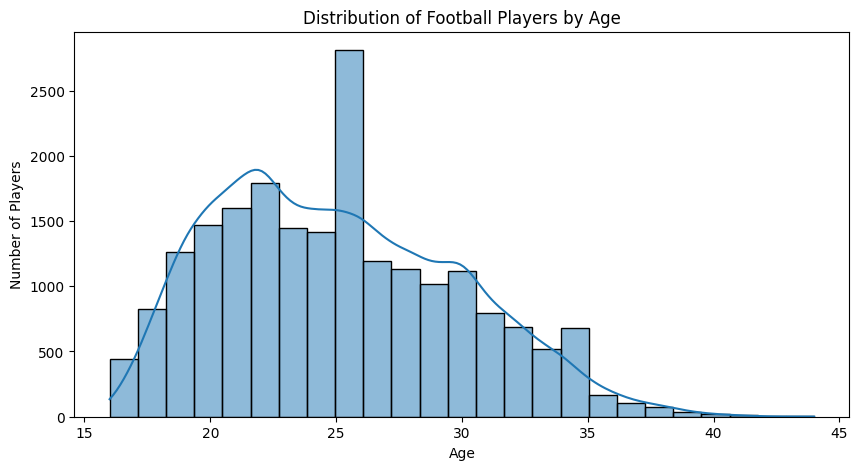

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=players,
    x="age",
    bins=25,
    kde=True
)

plt.title("Distribution of Football Players by Age")
plt.xlabel("Age")
plt.ylabel("Number of Players")

plt.show()

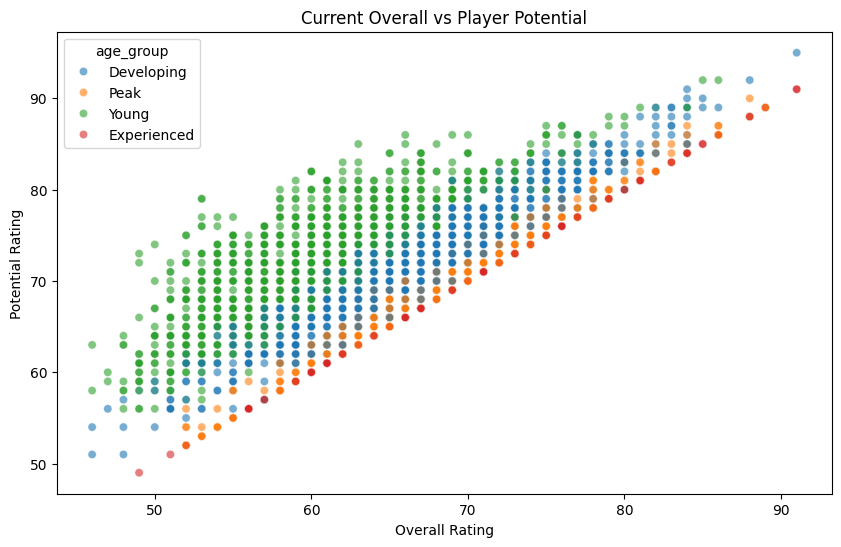

In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=players.sample(
        min(5000, len(players)),
        random_state=42
    ),
    x="overall",
    y="potential",
    hue="age_group",
    alpha=0.6
)

plt.title("Current Overall vs Player Potential")
plt.xlabel("Overall Rating")
plt.ylabel("Potential Rating")

plt.show()

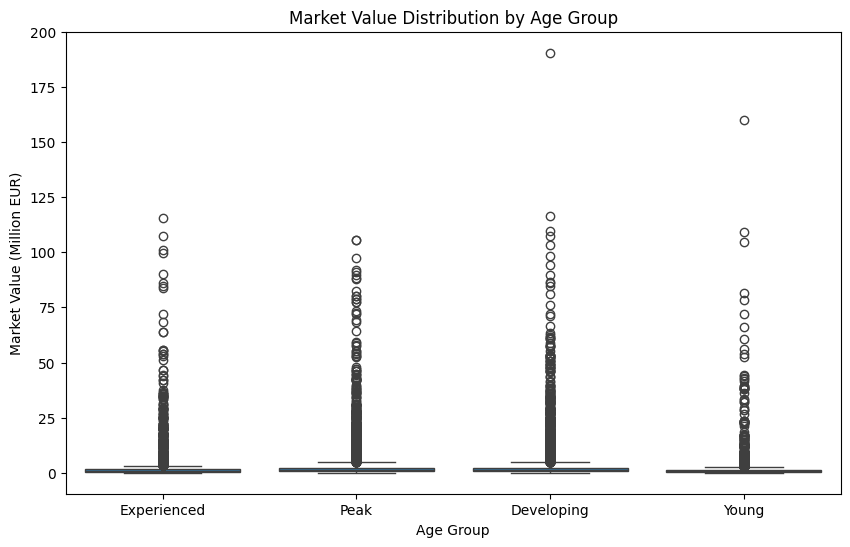

In [ ]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=players[
        players["value_eur"].notna()
    ],
    x="age_group",
    y="value_millions"
)

plt.title("Market Value Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Market Value (Million EUR)")

plt.show()

In [ ]:

players["primary_position"] = (
    players["player_positions"]
    .str.split(",")
    .str[0]
    .str.strip()
)

print("Primary positions created!")

display(
    players[
        ["short_name", "player_positions", "primary_position"]
    ].head(10)
)

Primary positions created!


,short_name,player_positions,primary_position
0,M. Pjanić,"CM, CDM",CM
1,J. Iličić,"CF, ST",CF
2,Paco Alcácer,ST,ST
3,Š. Vrsaljko,"RB, RM",RB
4,S. Arias,RB,RB
5,Rafinha,"CM, CAM",CM
6,A. Dragović,CB,CB
7,C. Bakambu,ST,ST
8,D. Samassékou,"CDM, CM",CDM
9,A. Taarabt,"CM, CAM",CM


In [ ]:
players.to_sql(
    "players",
    conn,
    if_exists="replace",
    index=False
)

print("SQL database updated!")

SQL database updated!


In [ ]:
query = """
SELECT
    primary_position,
    COUNT(*) AS player_count,
    ROUND(AVG(overall), 2) AS avg_overall,
    ROUND(AVG(potential), 2) AS avg_potential,
    ROUND(AVG(value_eur) / 1000000, 2) AS avg_value_millions
FROM players
WHERE primary_position IS NOT NULL
GROUP BY primary_position
ORDER BY player_count DESC;
"""

position_analysis = pd.read_sql_query(query, conn)

display(position_analysis)

,primary_position,player_count,avg_overall,avg_potential,avg_value_millions
0,CB,3620,65.85,70.66,2.49
1,ST,2877,65.25,70.33,2.65
2,CM,2429,64.94,70.84,3.06
3,GK,2311,63.97,69.45,1.78
4,CDM,1726,66.15,70.61,2.66
5,RB,1357,65.49,70.00,2.14
6,LB,1276,65.65,70.15,2.43
7,CAM,1154,65.97,71.83,3.30
8,RM,1060,65.66,70.56,2.51
9,LM,1018,65.57,70.88,2.49


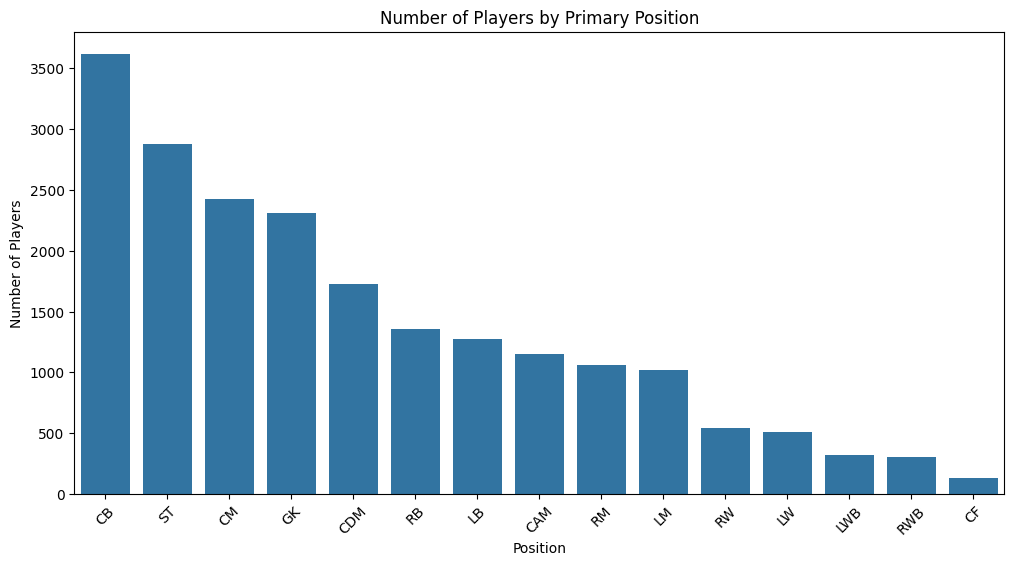

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=position_analysis,
    x="primary_position",
    y="player_count"
)

plt.title("Number of Players by Primary Position")
plt.xlabel("Position")
plt.ylabel("Number of Players")
plt.xticks(rotation=45)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import gc
import kagglehub

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported!")

dataset_path = kagglehub.dataset_download(
    "stefanoleone992/fifa-23-complete-player-dataset"
)

file_path = os.path.join(
    dataset_path,
    "male_players.csv"
)

selected_columns = [
    "player_id",
    "fifa_version",
    "fifa_update",
    "fifa_update_date",
    "short_name",
    "player_positions",
    "overall",
    "potential",
    "value_eur",
    "wage_eur",
    "age",
    "league_name",
    "club_name",
    "nationality_name",
    "pace",
    "shooting",
    "passing",
    "dribbling",
    "defending",
    "physic"
]

chunks = []

for chunk in pd.read_csv(
    file_path,
    usecols=selected_columns,
    chunksize=300_000,
    low_memory=True
):
    fifa23 = chunk[chunk["fifa_version"] == 23]

    if not fifa23.empty:
        chunks.append(fifa23)

players = pd.concat(chunks, ignore_index=True)

del chunks
gc.collect()

players["fifa_update_date"] = pd.to_datetime(
    players["fifa_update_date"],
    errors="coerce"
)

players = players.sort_values(
    ["fifa_update_date", "fifa_update"]
)

players = players.drop_duplicates(
    subset=["player_id"],
    keep="last"
).copy()

players.reset_index(drop=True, inplace=True)

players["primary_position"] = (
    players["player_positions"]
    .str.split(",")
    .str[0]
    .str.strip()
)

print("\nProject data restored successfully!")
print("Players:", len(players))
print("Unique IDs:", players["player_id"].nunique())

display(players.head())

Libraries imported!
Using Colab cache for faster access to the 'fifa-23-complete-player-dataset' dataset.

Project data restored successfully!
Players: 20621
Unique IDs: 20621


,player_id,fifa_version,fifa_update,fifa_update_date,short_name,player_positions,overall,potential,value_eur,wage_eur,...,league_name,club_name,nationality_name,pace,shooting,passing,dribbling,defending,physic,primary_position
0,180206,23,1,2022-09-01,M. Pjanić,"CM, CDM",81,81,20000000.0,145000.0,...,La Liga,FC Barcelona,Bosnia and Herzegovina,65.0,69.0,84.0,82.0,74.0,64.0,CM
1,200647,23,1,2022-09-01,J. Iličić,"CF, ST",81,81,12500000.0,65000.0,...,Serie A,Atalanta,Slovenia,75.0,81.0,82.0,84.0,40.0,64.0,CF
2,200454,23,1,2022-09-01,Paco Alcácer,ST,79,79,18000000.0,42000.0,...,La Liga,Villarreal,Spain,74.0,81.0,71.0,79.0,35.0,59.0,ST
3,203890,23,1,2022-09-01,Š. Vrsaljko,"RB, RM",79,79,NaN,NaN,...,NaN,NaN,Croatia,79.0,55.0,72.0,73.0,77.0,76.0,RB
4,204259,23,1,2022-09-01,S. Arias,RB,79,79,15000000.0,51000.0,...,La Liga,Atlético Madrid,Colombia,74.0,53.0,72.0,76.0,77.0,72.0,RB


In [ ]:
cm_players = players[
    players["primary_position"] == "CM"
].copy()

features = [
    "pace",
    "shooting",
    "passing",
    "dribbling",
    "defending",
    "physic"
]

cm_players = cm_players.dropna(subset=features)

cm_players = cm_players.drop_duplicates(
    subset=["player_id"]
).copy()

print("Central Midfielders Dataset")
print("=" * 40)
print("Number of players:", len(cm_players))
print("Number of features:", len(features))

display(cm_players[
    ["short_name", "age", "overall", "potential",
     "value_eur"] + features
].head(10))

Central Midfielders Dataset
Number of players: 2429
Number of features: 6


,short_name,age,overall,potential,value_eur,pace,shooting,passing,dribbling,defending,physic
0,M. Pjanić,32,81,81,20000000.0,65.0,69.0,84.0,82.0,74.0,64.0
5,Rafinha,29,78,78,13500000.0,66.0,73.0,79.0,84.0,69.0,62.0
9,A. Taarabt,33,75,75,3500000.0,66.0,69.0,75.0,84.0,64.0,69.0
10,Gabriel,28,75,75,5500000.0,59.0,72.0,74.0,75.0,75.0,79.0
17,João Novais,28,74,74,4200000.0,66.0,76.0,77.0,75.0,51.0,69.0
32,Míchel,33,72,72,1400000.0,39.0,66.0,78.0,72.0,57.0,51.0
45,L. Palmiero,26,71,73,2300000.0,67.0,63.0,72.0,74.0,65.0,62.0
69,M. Cavion,27,69,69,1500000.0,63.0,63.0,70.0,70.0,63.0,68.0
72,R. Niyaz,27,69,70,1600000.0,75.0,59.0,70.0,73.0,61.0,56.0
73,A. De Sart,25,69,72,1800000.0,65.0,64.0,68.0,69.0,68.0,64.0


In [ ]:

from sklearn.preprocessing import StandardScaler

X = cm_players[features].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardization completed!")
print("Scaled dataset shape:", X_scaled.shape)

display(pd.DataFrame(
    X_scaled,
    columns=features
).head())

Standardization completed!
Scaled dataset shape: (2429, 6)


,pace,shooting,passing,dribbling,defending,physic
0,-0.098384,1.268303,2.595185,2.223089,1.871267,0.025688
1,0.029615,1.695452,1.955371,2.503908,1.297958,-0.190213
2,0.029615,1.268303,1.443520,2.503908,0.724649,0.565440
3,-0.866380,1.588665,1.315557,1.240220,1.985929,1.644946
4,0.029615,2.015814,1.699446,1.240220,-0.765954,0.565440


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

k_values = range(2, 9)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(
            X_scaled,
            labels,
            sample_size=min(5000, len(X_scaled)),
            random_state=42
        )
    )

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(results)

,K,Inertia,Silhouette Score
0,2,8754.640426,0.320963
1,3,6969.640466,0.260765
2,4,6004.285096,0.262756
3,5,5347.413863,0.216158
4,6,4907.686685,0.212465
5,7,4626.025529,0.198883
6,8,4380.746337,0.179866


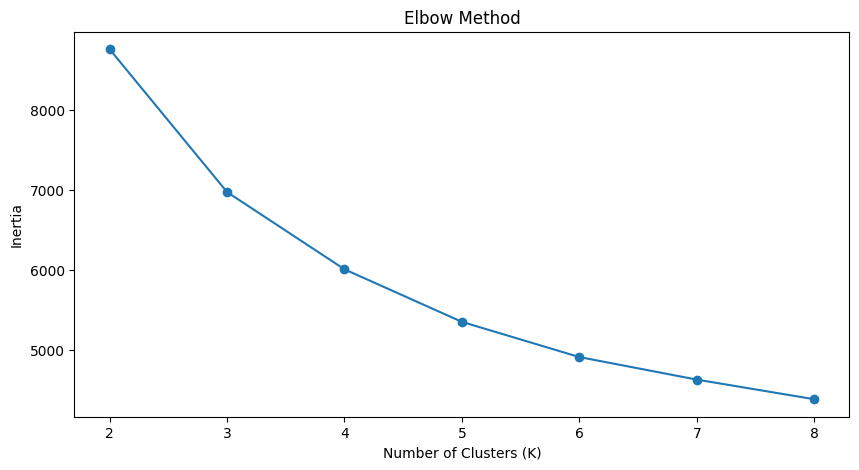

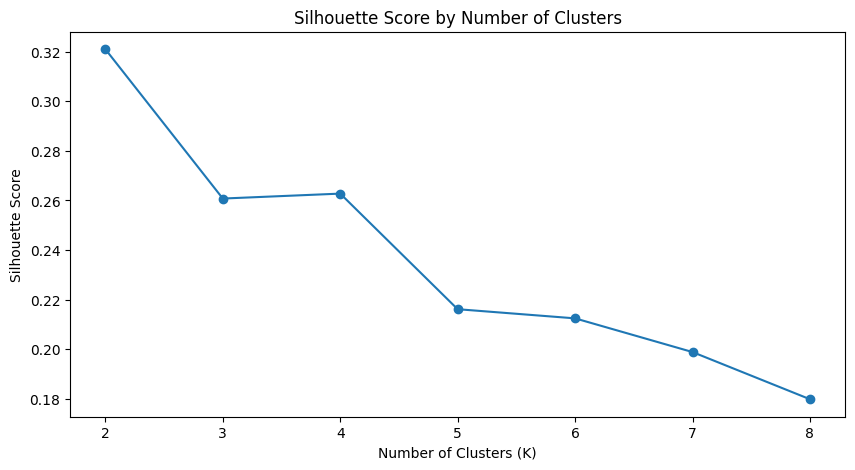

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    results["K"],
    results["Inertia"],
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    results["K"],
    results["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.show()

In [ ]:
best_k = int(
    results.loc[
        results["Silhouette Score"].idxmax(),
        "K"
    ]
)

kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cm_players["cluster"] = kmeans_final.fit_predict(X_scaled)

print("Selected number of clusters:", best_k)
print("\nPlayers in each cluster:")

print(cm_players["cluster"].value_counts().sort_index())

Selected number of clusters: 2

Players in each cluster:
cluster
0    1321
1    1108
Name: count, dtype: int64


In [ ]:

cluster_profile = cm_players.groupby("cluster").agg(
    player_count=("player_id", "count"),
    avg_age=("age", "mean"),
    avg_overall=("overall", "mean"),
    avg_potential=("potential", "mean"),
    avg_value=("value_eur", "mean"),
    avg_pace=("pace", "mean"),
    avg_shooting=("shooting", "mean"),
    avg_passing=("passing", "mean"),
    avg_dribbling=("dribbling", "mean"),
    avg_defending=("defending", "mean"),
    avg_physic=("physic", "mean")
).round(2)

display(cluster_profile)

,player_count,avg_age,avg_overall,avg_potential,avg_value,avg_pace,avg_shooting,avg_passing,avg_dribbling,avg_defending,avg_physic
cluster,,,,,,,,,,,
0,1321,26.52,70.04,73.10,5153482.89,66.52,63.32,68.86,70.69,63.08,69.18
1,1108,21.90,58.87,68.15,566355.01,64.88,49.74,57.59,60.77,51.24,57.30


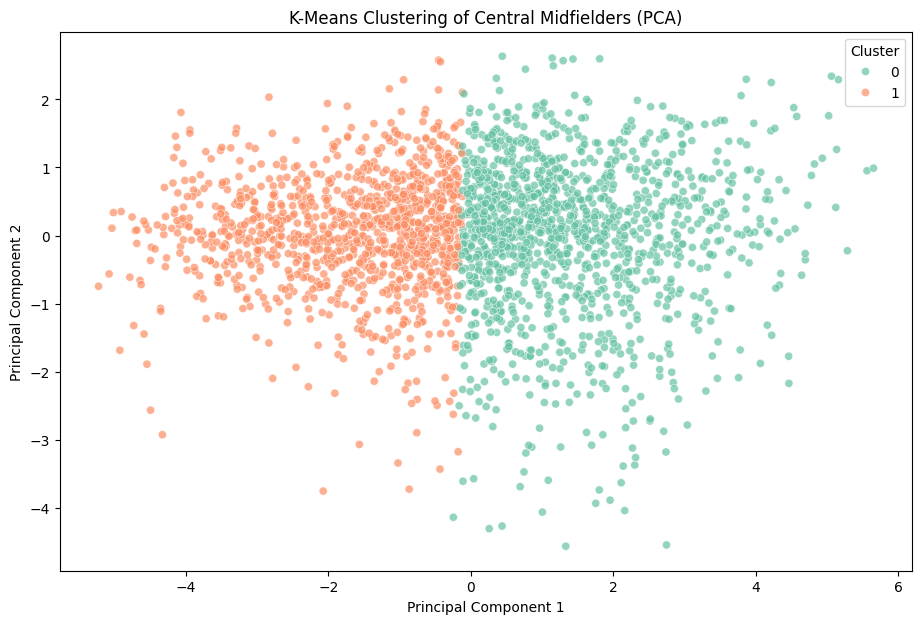

Explained variance: 80.02 %


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

cm_players["PCA1"] = X_pca[:, 0]
cm_players["PCA2"] = X_pca[:, 1]

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=cm_players,
    x="PCA1",
    y="PCA2",
    hue="cluster",
    palette="Set2",
    alpha=0.7,
    s=35
)

plt.title("K-Means Clustering of Central Midfielders (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.show()

print(
    "Explained variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

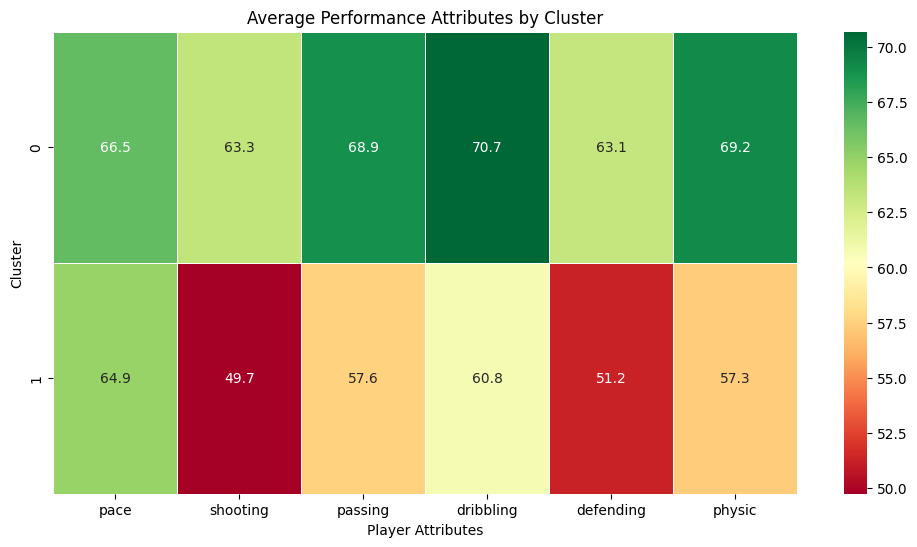

In [ ]:

cluster_means = cm_players.groupby("cluster")[features].mean()

plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_means,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    linewidths=0.5
)

plt.title("Average Performance Attributes by Cluster")
plt.xlabel("Player Attributes")
plt.ylabel("Cluster")

plt.show()

In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features = [
    "pace",
    "shooting",
    "passing",
    "dribbling",
    "defending",
    "physic"
]

cm_players = players[
    players["primary_position"] == "CM"
].copy()

cm_players = cm_players.dropna(
    subset=features
).copy()

cm_players["potential_gap"] = (
    cm_players["potential"] - cm_players["overall"]
)

cm_players = cm_players.drop_duplicates(
    subset=["player_id"]
).copy()

X = cm_players[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cm_players["cluster"] = kmeans_final.fit_predict(X_scaled)

print("K-Means successfully restored!")
print("Players:", len(cm_players))
print("\nCluster distribution:")
print(cm_players["cluster"].value_counts().sort_index())

K-Means successfully restored!
Players: 2429

Cluster distribution:
cluster
0     628
1     597
2    1204
Name: count, dtype: int64


In [ ]:
print("Available columns:")
print(cm_players.columns.tolist())

print("\nCluster column exists:",
      "cluster" in cm_players.columns)

Available columns:
['player_id', 'fifa_version', 'fifa_update', 'fifa_update_date', 'short_name', 'player_positions', 'overall', 'potential', 'value_eur', 'wage_eur', 'age', 'league_name', 'club_name', 'nationality_name', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'primary_position', 'potential_gap', 'value_millions', 'potential_ratio', 'cluster']

Cluster column exists: True


In [ ]:
for cluster_id in sorted(cm_players["cluster"].unique()):

    print(f"\nCLUSTER {cluster_id}")
    print("=" * 60)

    top_players = cm_players[
        cm_players["cluster"] == cluster_id
    ].sort_values(
        ["potential", "overall"],
        ascending=False
    )

    display(
        top_players[
            [
                "short_name",
                "age",
                "overall",
                "potential",
                "potential_gap",
                "value_eur",
                "pace",
                "shooting",
                "passing",
                "dribbling",
                "defending",
                "physic"
            ]
        ].head(10)
    )


CLUSTER 0


,short_name,age,overall,potential,potential_gap,value_eur,pace,shooting,passing,dribbling,defending,physic
2530,F. de Jong,25,87,92,5,116500000.0,82.0,69.0,86.0,87.0,77.0,78.0
2583,Pedri,19,85,92,7,104500000.0,79.0,67.0,81.0,87.0,68.0,74.0
2497,K. De Bruyne,31,91,91,0,107500000.0,74.0,88.0,93.0,87.0,63.0,77.0
2584,J. Bellingham,19,85,91,6,81500000.0,72.0,75.0,79.0,84.0,78.0,80.0
2582,F. Valverde,23,85,90,5,81000000.0,88.0,79.0,82.0,81.0,78.0,82.0
2550,N. Barella,25,86,89,3,89500000.0,79.0,76.0,83.0,84.0,78.0,81.0
3148,E. Camavinga,19,79,89,10,38000000.0,76.0,66.0,78.0,81.0,76.0,78.0
3154,Vitinha,22,79,89,10,39500000.0,73.0,68.0,79.0,83.0,67.0,55.0
2513,L. Modrić,36,88,88,0,29000000.0,73.0,76.0,89.0,88.0,72.0,66.0
2514,T. Kroos,32,88,88,0,72000000.0,53.0,81.0,90.0,81.0,71.0,68.0



CLUSTER 1


,short_name,age,overall,potential,potential_gap,value_eur,pace,shooting,passing,dribbling,defending,physic
2146,Dani Pérez,16,61,81,20,875000.0,64.0,54.0,63.0,66.0,50.0,49.0
18050,D. Gyabi,18,59,81,22,700000.0,65.0,45.0,57.0,62.0,52.0,67.0
17540,Berna,18,60,80,20,675000.0,72.0,49.0,61.0,59.0,53.0,54.0
17865,A. Wharton,18,59,80,21,700000.0,70.0,35.0,55.0,61.0,52.0,59.0
2277,C. Webster,18,58,80,22,650000.0,66.0,54.0,59.0,65.0,47.0,50.0
19059,D. Reid,17,56,80,24,450000.0,73.0,45.0,54.0,59.0,50.0,58.0
16111,Rodrigo,19,62,79,17,1000000.0,62.0,54.0,65.0,64.0,48.0,46.0
16856,H. Akman,17,61,79,18,825000.0,72.0,51.0,59.0,73.0,47.0,43.0
18001,T. O'Reilly,18,59,79,20,625000.0,61.0,56.0,60.0,65.0,51.0,47.0
14919,T. Milanese,19,63,78,15,1100000.0,67.0,53.0,66.0,69.0,36.0,42.0



CLUSTER 2


,short_name,age,overall,potential,potential_gap,value_eur,pace,shooting,passing,dribbling,defending,physic
11759,Mateus Fernandes,17,66,85,19,2100000.0,75.0,56.0,66.0,73.0,51.0,62.0
6765,M. Perrone,19,71,84,13,4400000.0,67.0,54.0,66.0,74.0,67.0,62.0
7646,Andrey Santos,18,70,84,14,3700000.0,75.0,56.0,66.0,73.0,62.0,68.0
9421,M. Kjaergaard,19,68,84,16,3100000.0,74.0,67.0,68.0,69.0,58.0,71.0
12704,C. Patino,18,65,84,19,1800000.0,64.0,47.0,64.0,67.0,60.0,59.0
12952,João Neves,17,65,84,19,1800000.0,70.0,48.0,66.0,70.0,57.0,55.0
13854,C. Chukwuemeka,18,64,84,20,1600000.0,65.0,59.0,64.0,70.0,50.0,57.0
15887,S. Raebiger,17,62,84,22,1200000.0,68.0,52.0,65.0,66.0,55.0,47.0
16848,L. Ulrich,17,61,84,23,1000000.0,76.0,59.0,61.0,68.0,45.0,63.0
4785,K. Fujimoto,23,74,83,9,9500000.0,77.0,70.0,72.0,75.0,52.0,52.0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import gc
import kagglehub

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

dataset_path = kagglehub.dataset_download(
    "stefanoleone992/fifa-23-complete-player-dataset"
)

file_path = os.path.join(dataset_path, "male_players.csv")

selected_columns = [
    "player_id", "fifa_version", "fifa_update",
    "fifa_update_date", "short_name", "player_positions",
    "overall", "potential", "value_eur", "wage_eur",
    "age", "league_name", "club_name", "nationality_name",
    "pace", "shooting", "passing", "dribbling",
    "defending", "physic"
]

chunks = []

for chunk in pd.read_csv(
    file_path,
    usecols=selected_columns,
    chunksize=300_000,
    low_memory=True
):
    fifa23 = chunk[chunk["fifa_version"] == 23]

    if not fifa23.empty:
        chunks.append(fifa23)

players = pd.concat(chunks, ignore_index=True)

del chunks
gc.collect()

print("Loaded rows:", len(players))

100%|██████████| 1.58G/1.58G [00:19<00:00, 87.7MB/s]

Extracting files...


Loaded rows: 166674


In [ ]:
players["fifa_update_date"] = pd.to_datetime(
    players["fifa_update_date"],
    errors="coerce"
)

players = players.sort_values(
    ["fifa_update_date", "fifa_update"]
)

players = players.drop_duplicates(
    subset=["player_id"],
    keep="last"
).copy()

players.reset_index(drop=True, inplace=True)

players["primary_position"] = (
    players["player_positions"]
    .str.split(",")
    .str[0]
    .str.strip()
)

players["potential_gap"] = (
    players["potential"] - players["overall"]
)

players["value_millions"] = (
    players["value_eur"] / 1_000_000
)

print("Final players:", len(players))
display(players.head())

Final players: 20621


,player_id,fifa_version,fifa_update,fifa_update_date,short_name,player_positions,overall,potential,value_eur,wage_eur,...,nationality_name,pace,shooting,passing,dribbling,defending,physic,primary_position,potential_gap,value_millions
0,180206,23,1,2022-09-01,M. Pjanić,"CM, CDM",81,81,20000000.0,145000.0,...,Bosnia and Herzegovina,65.0,69.0,84.0,82.0,74.0,64.0,CM,0,20.0
1,200647,23,1,2022-09-01,J. Iličić,"CF, ST",81,81,12500000.0,65000.0,...,Slovenia,75.0,81.0,82.0,84.0,40.0,64.0,CF,0,12.5
2,200454,23,1,2022-09-01,Paco Alcácer,ST,79,79,18000000.0,42000.0,...,Spain,74.0,81.0,71.0,79.0,35.0,59.0,ST,0,18.0
3,203890,23,1,2022-09-01,Š. Vrsaljko,"RB, RM",79,79,NaN,NaN,...,Croatia,79.0,55.0,72.0,73.0,77.0,76.0,RB,0,NaN
4,204259,23,1,2022-09-01,S. Arias,RB,79,79,15000000.0,51000.0,...,Colombia,74.0,53.0,72.0,76.0,77.0,72.0,RB,0,15.0


In [ ]:
features = [
    "pace", "shooting", "passing",
    "dribbling", "defending", "physic"
]

cm_players = players[
    players["primary_position"] == "CM"
].copy()

cm_players = cm_players.dropna(subset=features).copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(cm_players[features])

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cm_players["cluster"] = kmeans_final.fit_predict(X_scaled)

print("Central midfielders:", len(cm_players))
print(cm_players["cluster"].value_counts().sort_index())

Central midfielders: 2429
cluster
0     628
1     597
2    1204
Name: count, dtype: int64


In [ ]:
cluster_profile = cm_players.groupby("cluster").agg(
    player_count=("player_id", "count"),
    avg_age=("age", "mean"),
    avg_overall=("overall", "mean"),
    avg_potential=("potential", "mean"),
    avg_potential_gap=("potential_gap", "mean"),
    median_value=("value_eur", "median"),
    avg_pace=("pace", "mean"),
    avg_shooting=("shooting", "mean"),
    avg_passing=("passing", "mean"),
    avg_dribbling=("dribbling", "mean"),
    avg_defending=("defending", "mean"),
    avg_physic=("physic", "mean")
).round(2)

display(cluster_profile)

,player_count,avg_age,avg_overall,avg_potential,avg_potential_gap,median_value,avg_pace,avg_shooting,avg_passing,avg_dribbling,avg_defending,avg_physic
cluster,,,,,,,,,,,,
0,628,27.31,74.02,76.23,2.21,4000000.0,65.69,67.65,73.27,74.20,66.91,71.38
1,597,20.46,55.79,67.23,11.44,300000.0,63.97,45.82,54.53,57.93,48.01,54.03
2,1204,24.87,64.74,69.83,5.09,975000.0,66.70,57.24,63.29,66.06,57.66,64.61


In [ ]:
scouting_players = cm_players.dropna(
    subset=[
        "overall",
        "potential",
        "potential_gap",
        "value_eur",
        "age"
    ]
).copy()

scouting_players = scouting_players[
    scouting_players["value_eur"] > 0
].copy()

scouting_players["performance_score"] = (
    scouting_players.groupby("cluster")["overall"].rank(pct=True)
)

scouting_players["potential_score"] = (
    scouting_players.groupby("cluster")["potential"].rank(pct=True)
)

scouting_players["development_score"] = (
    scouting_players.groupby("cluster")["potential_gap"].rank(pct=True)
)

scouting_players["affordability_score"] = (
    1 - scouting_players.groupby("cluster")["value_eur"].rank(pct=True)
)

scouting_players["age_score"] = (
    1 - (scouting_players["age"] - 16) / (35 - 16)
).clip(0, 1)

# Final Scouting Value Score
scouting_players["scouting_score"] = (
    0.25 * scouting_players["performance_score"] +
    0.30 * scouting_players["potential_score"] +
    0.20 * scouting_players["development_score"] +
    0.15 * scouting_players["affordability_score"] +
    0.10 * scouting_players["age_score"]
)

scouting_players = scouting_players.sort_values(
    "scouting_score",
    ascending=False
)

display(
    scouting_players[
        [
            "short_name",
            "age",
            "overall",
            "potential",
            "potential_gap",
            "value_eur",
            "cluster",
            "scouting_score"
        ]
    ].head(20)
)

,short_name,age,overall,potential,potential_gap,value_eur,cluster,scouting_score
2146,Dani Pérez,16,61,81,20,875000.0,1,0.825293
7646,Andrey Santos,18,70,84,14,3700000.0,2,0.819378
6765,M. Perrone,19,71,84,13,4400000.0,2,0.815590
2583,Pedri,19,85,92,7,104500000.0,0,0.811461
16856,H. Akman,17,61,79,18,825000.0,1,0.804536
3148,E. Camavinga,19,79,89,10,38000000.0,0,0.804146
2999,Gavi,17,80,87,7,39000000.0,0,0.803700
17540,Berna,18,60,80,20,675000.0,1,0.802832
2584,J. Bellingham,19,85,91,6,81500000.0,0,0.800448
9424,A. Scott,18,68,83,15,2800000.0,2,0.799781


In [ ]:
shortlist = scouting_players[
    (scouting_players["age"] <= 23) &
    (scouting_players["potential"] >= 80) &
    (scouting_players["overall"] >= 60)
].copy()

shortlist = shortlist.sort_values(
    "scouting_score",
    ascending=False
)

display(
    shortlist[
        [
            "short_name",
            "age",
            "overall",
            "potential",
            "potential_gap",
            "value_eur",
            "cluster",
            "scouting_score"
        ]
    ].head(20)
)

,short_name,age,overall,potential,potential_gap,value_eur,cluster,scouting_score
2146,Dani Pérez,16,61,81,20,875000.0,1,0.825293
7646,Andrey Santos,18,70,84,14,3700000.0,2,0.819378
6765,M. Perrone,19,71,84,13,4400000.0,2,0.815590
2583,Pedri,19,85,92,7,104500000.0,0,0.811461
3148,E. Camavinga,19,79,89,10,38000000.0,0,0.804146
2999,Gavi,17,80,87,7,39000000.0,0,0.803700
17540,Berna,18,60,80,20,675000.0,1,0.802832
2584,J. Bellingham,19,85,91,6,81500000.0,0,0.800448
9424,A. Scott,18,68,83,15,2800000.0,2,0.799781
9421,M. Kjaergaard,19,68,84,16,3100000.0,2,0.796575


In [ ]:
# Calculate value-for-money indicators

shortlist["quality_per_million"] = (
    shortlist["overall"] /
    (shortlist["value_eur"] / 1_000_000)
)

shortlist["potential_per_million"] = (
    shortlist["potential"] /
    (shortlist["value_eur"] / 1_000_000)
)

# Sort by potential relative to estimated value
value_shortlist = shortlist.sort_values(
    "potential_per_million",
    ascending=False
)

display(
    value_shortlist[
        [
            "short_name",
            "age",
            "overall",
            "potential",
            "value_eur",
            "cluster",
            "scouting_score",
            "quality_per_million",
            "potential_per_million"
        ]
    ].head(15)
)

,short_name,age,overall,potential,value_eur,cluster,scouting_score,quality_per_million,potential_per_million
17395,O. Fraulo,18,60,80,675000.0,2,0.695667,88.888889,118.518519
17540,Berna,18,60,80,675000.0,1,0.802832,88.888889,118.518519
17351,A. Kamara,17,60,82,775000.0,2,0.695859,77.419355,105.806452
16591,S. Oulad M'Hand,18,61,80,825000.0,2,0.690430,73.939394,96.969697
16738,A. Foti,18,61,80,825000.0,2,0.690430,73.939394,96.969697
2146,Dani Pérez,16,61,81,875000.0,1,0.825293,69.714286,92.571429
16735,L. Hall,17,61,81,875000.0,2,0.696192,69.714286,92.571429
16848,L. Ulrich,17,61,84,1000000.0,2,0.690248,61.000000,84.000000
15651,O. Holm,19,62,80,1000000.0,2,0.687307,62.000000,80.000000
15887,S. Raebiger,17,62,84,1200000.0,2,0.694654,51.666667,70.000000


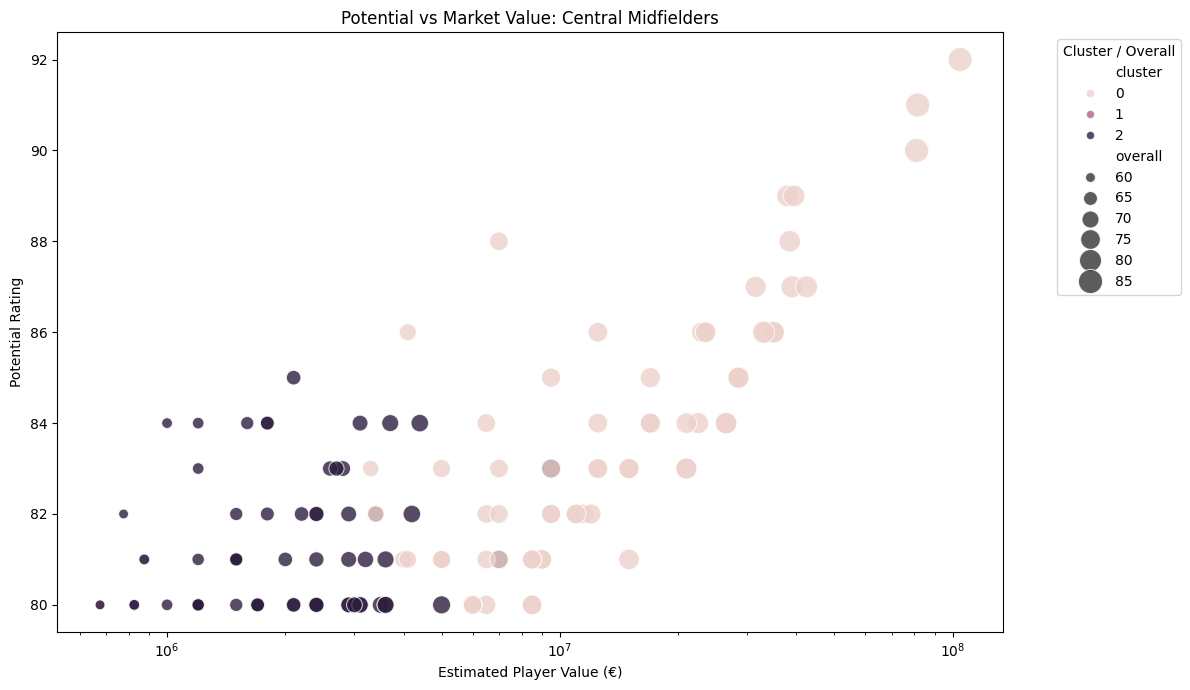

In [ ]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=shortlist,
    x="value_eur",
    y="potential",
    hue="cluster",
    size="overall",
    sizes=(50, 300),
    alpha=0.8
)

plt.title("Potential vs Market Value: Central Midfielders")
plt.xlabel("Estimated Player Value (€)")
plt.ylabel("Potential Rating")

plt.xscale("log")
plt.legend(title="Cluster / Overall", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [2]:
print("players:", "players" in globals())
print("cm_players:", "cm_players" in globals())
print("scouting_players:", "scouting_players" in globals())
print("shortlist:", "shortlist" in globals())

players: False
cm_players: False
scouting_players: False
shortlist: False


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import gc
import kagglehub

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Download FIFA 23 dataset
print("Step 1: Downloading dataset...")

dataset_path = kagglehub.dataset_download(
    "stefanoleone992/fifa-23-complete-player-dataset"
)

file_path = os.path.join(dataset_path, "male_players.csv")

# 2. Load only FIFA 23 records using chunks
print("Step 2: Loading FIFA 23 records...")

selected_columns = [
    "player_id", "fifa_version", "fifa_update",
    "fifa_update_date", "short_name", "player_positions",
    "overall", "potential", "value_eur", "wage_eur",
    "age", "league_name", "club_name", "nationality_name",
    "pace", "shooting", "passing", "dribbling",
    "defending", "physic"
]

chunks = []

for chunk in pd.read_csv(
    file_path,
    usecols=selected_columns,
    chunksize=300_000,
    low_memory=True
):
    fifa23 = chunk[chunk["fifa_version"] == 23]

    if not fifa23.empty:
        chunks.append(fifa23)

players = pd.concat(chunks, ignore_index=True)

del chunks
gc.collect()

# 3. Data cleaning
print("Step 3: Cleaning data...")

players["fifa_update_date"] = pd.to_datetime(
    players["fifa_update_date"],
    errors="coerce"
)

players = players.sort_values(
    ["fifa_update_date", "fifa_update"]
)

players = players.drop_duplicates(
    subset=["player_id"],
    keep="last"
).copy()

players.reset_index(drop=True, inplace=True)

# 4. Feature engineering
players["primary_position"] = (
    players["player_positions"]
    .str.split(",")
    .str[0]
    .str.strip()
)

players["potential_gap"] = (
    players["potential"] - players["overall"]
)

players["value_millions"] = (
    players["value_eur"] / 1_000_000
)

print("Final players:", len(players))

# 5. Select central midfielders
print("Step 4: Preparing central midfielders...")

features = [
    "pace", "shooting", "passing",
    "dribbling", "defending", "physic"
]

cm_players = players[
    players["primary_position"] == "CM"
].copy()

cm_players = cm_players.dropna(
    subset=features
).copy()

# 6. Standardization and K-Means
print("Step 5: Training K-Means...")

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    cm_players[features]
)

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cm_players["cluster"] = kmeans_final.fit_predict(
    X_scaled
)

print("Central midfielders:", len(cm_players))
print("Cluster distribution:")
print(cm_players["cluster"].value_counts().sort_index())

# 7. Create Scouting Value Score
print("Step 6: Calculating Scouting Score...")

scouting_players = cm_players.dropna(
    subset=[
        "overall", "potential",
        "potential_gap", "value_eur", "age"
    ]
).copy()

scouting_players = scouting_players[
    scouting_players["value_eur"] > 0
].copy()

scouting_players["performance_score"] = (
    scouting_players.groupby("cluster")["overall"].rank(pct=True)
)

scouting_players["potential_score"] = (
    scouting_players.groupby("cluster")["potential"].rank(pct=True)
)

scouting_players["development_score"] = (
    scouting_players.groupby("cluster")["potential_gap"].rank(pct=True)
)

scouting_players["affordability_score"] = (
    1 - scouting_players.groupby("cluster")["value_eur"].rank(pct=True)
)

scouting_players["age_score"] = (
    1 - (scouting_players["age"] - 16) / (35 - 16)
).clip(0, 1)

scouting_players["scouting_score"] = (
    0.25 * scouting_players["performance_score"] +
    0.30 * scouting_players["potential_score"] +
    0.20 * scouting_players["development_score"] +
    0.15 * scouting_players["affordability_score"] +
    0.10 * scouting_players["age_score"]
)

# 8. Create shortlist
shortlist = scouting_players[
    (scouting_players["age"] <= 23) &
    (scouting_players["potential"] >= 80) &
    (scouting_players["overall"] >= 60)
].copy()

shortlist = shortlist.sort_values(
    "scouting_score",
    ascending=False
)

# 9. Baseline comparison
baseline_top20 = shortlist.sort_values(
    "potential",
    ascending=False
).head(20)

model_top20 = shortlist.sort_values(
    "scouting_score",
    ascending=False
).head(20)

overlap = set(baseline_top20["player_id"]).intersection(
    set(model_top20["player_id"])
)

comparison = pd.DataFrame({
    "Baseline (Potential)": [
        baseline_top20["overall"].mean(),
        baseline_top20["potential"].mean(),
        baseline_top20["age"].mean(),
        baseline_top20["value_eur"].mean()
    ],
    "Our Model (Scouting Score)": [
        model_top20["overall"].mean(),
        model_top20["potential"].mean(),
        model_top20["age"].mean(),
        model_top20["value_eur"].mean()
    ]
}, index=[
    "Average Overall",
    "Average Potential",
    "Average Age",
    "Average Estimated Value (€)"
])

# 10. Final Moneyball shortlist
moneyball_shortlist = scouting_players[
    (scouting_players["age"] <= 23) &
    (scouting_players["overall"] >= 65) &
    (scouting_players["potential"] >= 80) &
    (scouting_players["value_eur"] <= 5_000_000)
].copy()

moneyball_shortlist = moneyball_shortlist.sort_values(
    "scouting_score",
    ascending=False
)

# 11. Results
print("\n========== PROJECT RESULTS ==========")

print("Final FIFA 23 players:", len(players))
print("Central midfielders:", len(cm_players))
print("Scored players:", len(scouting_players))
print("Shortlist size:", len(shortlist))

print("\nBaseline vs Model:")
print("Common players in top 20:", len(overlap))
print("Overlap percentage:", round(len(overlap) / 20 * 100, 2), "%")

print("\nComparison:")
display(comparison.round(2))

print("\nFinal Moneyball Shortlist:")
display(
    moneyball_shortlist[
        [
            "short_name", "age", "overall",
            "potential", "potential_gap",
            "value_eur", "cluster", "scouting_score"
        ]
    ].head(15)
)

print("\nPipeline successfully restored!")

Step 1: Downloading dataset...


100%|██████████| 1.58G/1.58G [00:18<00:00, 92.3MB/s]

Extracting files...


Step 2: Loading FIFA 23 records...
Step 3: Cleaning data...
Final players: 20621
Step 4: Preparing central midfielders...
Step 5: Training K-Means...
Central midfielders: 2429
Cluster distribution:
cluster
0     628
1     597
2    1204
Name: count, dtype: int64
Step 6: Calculating Scouting Score...

========== PROJECT RESULTS ==========
Final FIFA 23 players: 20621
Central midfielders: 2429
Scored players: 2422
Shortlist size: 134

Baseline vs Model:
Common players in top 20: 7
Overlap percentage: 35.0 %

Comparison:


,Baseline (Potential),Our Model (Scouting Score)
Average Overall,78.75,72.45
Average Potential,87.35,84.40
Average Age,20.65,19.30
Average Estimated Value (€),37730000.00,21112500.00



Final Moneyball Shortlist:


,short_name,age,overall,potential,potential_gap,value_eur,cluster,scouting_score
7646,Andrey Santos,18,70,84,14,3700000.0,2,0.819378
6765,M. Perrone,19,71,84,13,4400000.0,2,0.815590
9424,A. Scott,18,68,83,15,2800000.0,2,0.799781
9421,M. Kjaergaard,19,68,84,16,3100000.0,2,0.796575
8388,L. Ugochukwu,18,69,81,12,3200000.0,2,0.795937
6746,Antonio Blanco,21,71,82,11,4200000.0,2,0.790185
8343,Adrián Bernabé,21,69,82,13,3400000.0,2,0.787192
9431,E. Bove,20,68,82,14,2900000.0,2,0.783727
8360,J. Nardoni,19,69,80,11,3000000.0,2,0.781093
7574,M. Portanova,22,70,81,11,3600000.0,2,0.777336



Pipeline successfully restored!


In [5]:
# Same candidate pool for both methods
candidate_pool = scouting_players[
    (scouting_players["age"] <= 23) &
    (scouting_players["overall"] >= 65) &
    (scouting_players["potential"] >= 80) &
    (scouting_players["value_eur"] <= 5_000_000)
].copy()

# Baseline: Potential only
baseline_15 = candidate_pool.sort_values(
    "potential",
    ascending=False
).head(15)

# Our model: Scouting Score
model_15 = candidate_pool.sort_values(
    "scouting_score",
    ascending=False
).head(15)

# Compare both approaches
evaluation = pd.DataFrame({
    "Baseline": [
        baseline_15["overall"].mean(),
        baseline_15["potential"].mean(),
        baseline_15["age"].mean(),
        baseline_15["value_eur"].mean(),
        baseline_15["value_eur"].sum()
    ],
    "Scouting Score": [
        model_15["overall"].mean(),
        model_15["potential"].mean(),
        model_15["age"].mean(),
        model_15["value_eur"].mean(),
        model_15["value_eur"].sum()
    ]
}, index=[
    "Average Overall",
    "Average Potential",
    "Average Age",
    "Average Value (€)",
    "Total Squad Cost (€)"
])

display(evaluation.round(2))

# Calculate cost reduction
baseline_cost = baseline_15["value_eur"].sum()
model_cost = model_15["value_eur"].sum()

cost_reduction = (
    (baseline_cost - model_cost) / baseline_cost * 100
)

print("Estimated cost reduction:", round(cost_reduction, 2), "%")
print("Candidate pool size:", len(candidate_pool))

print("\nOur Top 15 candidates:")
display(
    model_15[
        [
            "short_name", "age", "overall",
            "potential", "value_eur",
            "scouting_score"
        ]
    ]
)

,Baseline,Scouting Score
Average Overall,68.33,68.80
Average Potential,83.47,82.07
Average Age,18.93,19.47
Average Value (€),3160000.00,3206666.67
Total Squad Cost (€),47400000.00,48100000.00


Estimated cost reduction: -1.48 %
Candidate pool size: 48

Our Top 15 candidates:


,short_name,age,overall,potential,value_eur,scouting_score
7646,Andrey Santos,18,70,84,3700000.0,0.819378
6765,M. Perrone,19,71,84,4400000.0,0.815590
9424,A. Scott,18,68,83,2800000.0,0.799781
9421,M. Kjaergaard,19,68,84,3100000.0,0.796575
8388,L. Ugochukwu,18,69,81,3200000.0,0.795937
6746,Antonio Blanco,21,71,82,4200000.0,0.790185
8343,Adrián Bernabé,21,69,82,3400000.0,0.787192
9431,E. Bove,20,68,82,2900000.0,0.783727
8360,J. Nardoni,19,69,80,3000000.0,0.781093
7574,M. Portanova,22,70,81,3600000.0,0.777336


In [6]:
# Export project results
players.to_csv("/content/players_cleaned.csv", index=False)

cm_players.to_csv("/content/clustered_midfielders.csv", index=False)

moneyball_shortlist.to_csv(
    "/content/moneyball_shortlist.csv",
    index=False
)

comparison.to_csv("/content/baseline_comparison.csv")

print("All project results saved successfully!")

All project results saved successfully!


In [7]:
# Alternative budget-oriented scoring model

candidate_pool = scouting_players[
    (scouting_players["age"] <= 23) &
    (scouting_players["overall"] >= 65) &
    (scouting_players["potential"] >= 80) &
    (scouting_players["value_eur"] <= 5_000_000)
].copy()

candidate_pool["budget_score"] = (
    0.20 * candidate_pool["performance_score"] +
    0.25 * candidate_pool["potential_score"] +
    0.15 * candidate_pool["development_score"] +
    0.30 * candidate_pool["affordability_score"] +
    0.10 * candidate_pool["age_score"]
)

budget_top15 = candidate_pool.sort_values(
    "budget_score",
    ascending=False
).head(15)

display(
    budget_top15[
        [
            "short_name",
            "age",
            "overall",
            "potential",
            "potential_gap",
            "value_eur",
            "scouting_score",
            "budget_score"
        ]
    ]
)

,short_name,age,overall,potential,potential_gap,value_eur,scouting_score,budget_score
7646,Andrey Santos,18,70,84,14,3700000.0,0.819378,0.674844
6765,M. Perrone,19,71,84,13,4400000.0,0.815590,0.670661
9424,A. Scott,18,68,83,15,2800000.0,0.799781,0.664952
9421,M. Kjaergaard,19,68,84,16,3100000.0,0.796575,0.658483
8388,L. Ugochukwu,18,69,81,12,3200000.0,0.795937,0.658364
11759,Mateus Fernandes,17,66,85,19,2100000.0,0.772750,0.656832
7607,M. Baturina,19,70,86,16,4100000.0,0.680633,0.649202
9431,E. Bove,20,68,82,14,2900000.0,0.783727,0.649043
6012,F. Díaz,19,72,83,11,5000000.0,0.699122,0.648961
6746,Antonio Blanco,21,71,82,11,4200000.0,0.790185,0.648850


In [8]:
# Get top 15 from each approach

baseline_15 = candidate_pool.sort_values(
    "potential", ascending=False
).head(15)

original_15 = candidate_pool.sort_values(
    "scouting_score", ascending=False
).head(15)

budget_15 = candidate_pool.sort_values(
    "budget_score", ascending=False
).head(15)

# Build comparison
methods = {
    "Baseline": baseline_15,
    "Scouting Score": original_15,
    "Budget Score": budget_15
}

results = []

for method_name, df in methods.items():
    results.append({
        "Method": method_name,
        "Avg Overall": df["overall"].mean(),
        "Avg Potential": df["potential"].mean(),
        "Avg Age": df["age"].mean(),
        "Avg Player Value": df["value_eur"].mean(),
        "Total Squad Cost": df["value_eur"].sum()
    })

method_comparison = pd.DataFrame(results)

display(method_comparison.round(2))

,Method,Avg Overall,Avg Potential,Avg Age,Avg Player Value,Total Squad Cost
0,Baseline,68.33,83.47,18.93,3160000.00,47400000.0
1,Scouting Score,68.80,82.07,19.47,3206666.67,48100000.0
2,Budget Score,68.80,82.87,19.00,3286666.67,49300000.0
